# Liver Patient Classification

## **Importació de llibreries i configuració bàsica**



In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from pandas.plotting import scatter_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, RepeatedStratifiedKFold, ParameterGrid, train_test_split, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.preprocessing import RobustScaler, PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import f1_score, make_scorer, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, BaggingClassifier, ExtraTreesClassifier, VotingClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import boxcox
from sklearn.naive_bayes import GaussianNB

Carreguem les dades

In [2]:
X_train_raw = pd.read_csv("train_features_ILDS.csv", header = None)
y_train_raw = pd.read_csv("train_labels_ILDS.csv", header=None).values.ravel()
X_test_raw = pd.read_csv("test_data_ILDS.csv", header=None)

Configuració bàsica

In [3]:
X_train_raw.columns = ["Age", "Female", "TB", "DB", "Alkphos", "Sgpt", "Sgot", "TP", "ALB", "A/R"]
X_test_raw.columns = ["Age", "Female", "TB", "DB", "Alkphos", "Sgpt", "Sgot", "TP", "ALB", "A/R"]

Dividim les dades, abans del preprocessament, per la validació externa

In [4]:
X_train_for_search, X_validation_external_raw, y_train_for_search, y_validation_external = train_test_split(
  X_train_raw, y_train_raw, test_size=0.20, random_state=42, stratify=y_train_raw)

In [5]:
X_train = X_train_for_search.reset_index(drop=True)
X_validation_external_raw = X_validation_external_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

## **PREPROCESSAT**

Per tal de realitzar el preprocessat el que farem serà usar una còpia de les dades per justificar, analitzar i definir les transformacions que finalment s'implementen de manera segura i automatitzada dins del pipeline mitjançant la funció preprocess_features.

###  *Anàlisis general*



In [6]:
X_train.describe()

,Age,Female,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,A/R
count,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000
mean,44.710811,0.248649,3.269459,1.411081,284.886486,76.472973,97.478378,6.384595,3.089730,0.940676
std,16.002376,0.432815,6.139429,2.519918,216.076126,173.055376,214.927632,1.053813,0.789259,0.324339
min,4.000000,0.000000,0.500000,0.100000,75.000000,10.000000,11.000000,2.700000,0.900000,0.300000
25%,32.250000,0.000000,0.800000,0.200000,176.000000,23.000000,24.250000,5.700000,2.525000,0.700000
50%,45.000000,0.000000,1.000000,0.300000,209.500000,35.000000,41.000000,6.400000,3.000000,0.900000
75%,57.000000,0.000000,2.700000,1.275000,296.750000,60.000000,83.500000,7.100000,3.700000,1.100000
max,78.000000,1.000000,75.000000,17.100000,1620.000000,2000.000000,2946.000000,9.500000,5.500000,2.800000


In [7]:
X_train.head()

,Age,Female,TB,DB,Alkphos,Sgpt,Sgot,TP,ALB,A/R
0,55,1,0.8,0.2,225,14,23,6.1,3.3,1.20
1,34,0,8.7,4.0,298,58,138,5.8,2.4,0.70
2,45,1,0.8,0.2,165,22,18,8.2,4.1,1.00
3,32,0,0.7,0.2,276,102,190,6.0,2.9,0.93
4,45,0,1.3,0.6,166,49,42,5.6,2.5,0.80


Observem que tenim rangs de valors molt diferents, cal normalitzar-los. Comprovem abans si tenim NAs

### *Presencia de Nas*

In [8]:
X_train.isna().sum()

Age        0
Female     0
TB         0
DB         0
Alkphos    0
Sgpt       0
Sgot       0
TP         0
ALB        0
A/R        0
dtype: int64

Veiem que no hi ha presència de NAs. Proseguim amb el tractament de outliers

### *Tractament d'outliers*

Detectem primer si en tenim. Analitzem els boxplots i percentatges de la presència d'outliers de les variables numèriques.

      TB | Total: 370 | Small:   0 | Big:  55 | Total: 14.86%
      DB | Total: 370 | Small:   0 | Big:  54 | Total: 14.59%
 Alkphos | Total: 370 | Small:   0 | Big:  42 | Total: 11.35%
    Sgpt | Total: 370 | Small:   0 | Big:  44 | Total: 11.89%
    Sgot | Total: 370 | Small:   0 | Big:  44 | Total: 11.89%
      TP | Total: 370 | Small:   4 | Big:   1 | Total:  1.35%
     ALB | Total: 370 | Small:   0 | Big:   2 | Total:  0.54%
     A/R | Total: 370 | Small:   0 | Big:   7 | Total:  1.89%


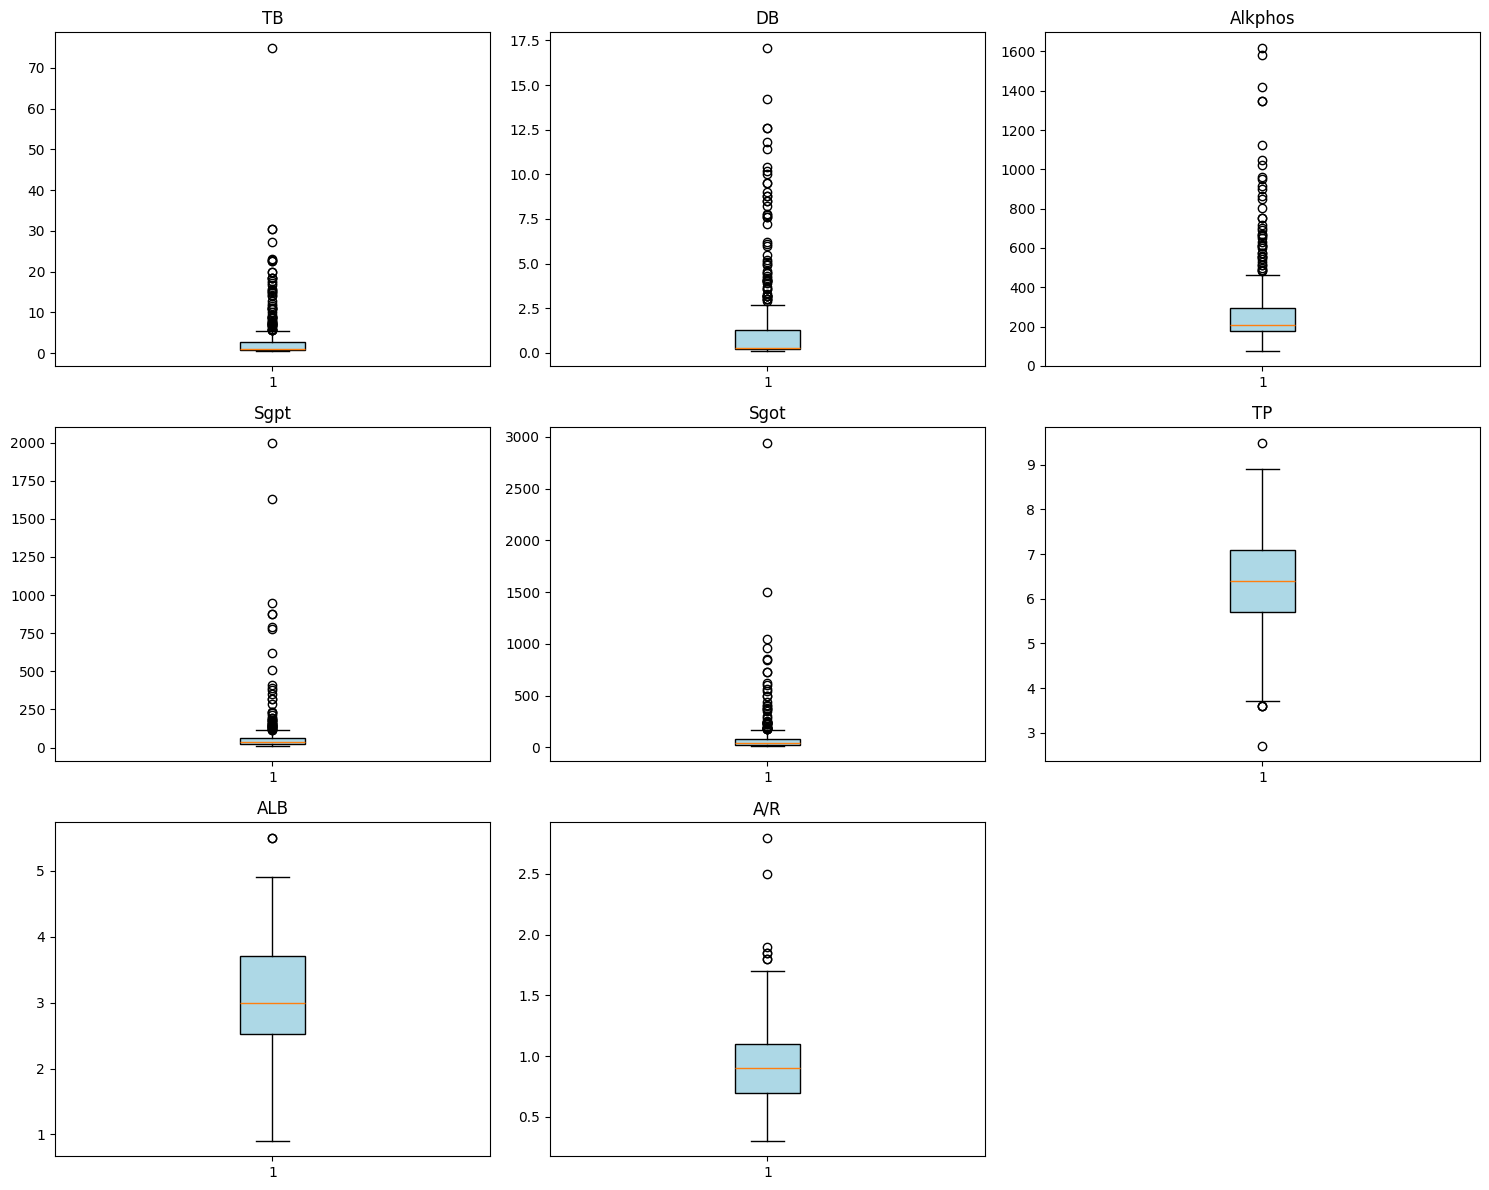

In [9]:
# Variables numèriques contínues
numeric_continuous_features = ["TB", "DB", "Alkphos", "Sgpt", "Sgot", "TP", "ALB", "A/R"]

cols = 3
rows = (len(numeric_continuous_features) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

for i, feature in enumerate(numeric_continuous_features):
    Q1 = X_train[feature].quantile(0.25)
    Q3 = X_train[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    small_outliers = (X_train[feature] < lower_bound).sum()
    big_outliers = (X_train[feature] > upper_bound).sum()
    total_outliers = small_outliers + big_outliers
    total_pct = 100 * total_outliers / len(X_train)

    print(f'{feature:>8} | Total: {len(X_train):>3} | '
          f'Small: {small_outliers:>3} | Big: {big_outliers:>3} | '
          f'Total: {total_pct:>5.2f}%')

    axes[i].boxplot(X_train[feature], vert=True, patch_artist=True,
                    boxprops=dict(facecolor="lightblue"))
    axes[i].set_title(feature)

# Eliminar subplots buits
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Tot i haver-hi una presència gran d'algunes variables d'outliers, decidirem no treure'ls ja que ens trobem en un context mèdic i són de molta importancia totes les observacions. A més, hem provat a treure'ls i hem obtingut un pitjor valor de F1. Per tot això, decidirem no treure'ls.

### *Gaussianitat de les variables*

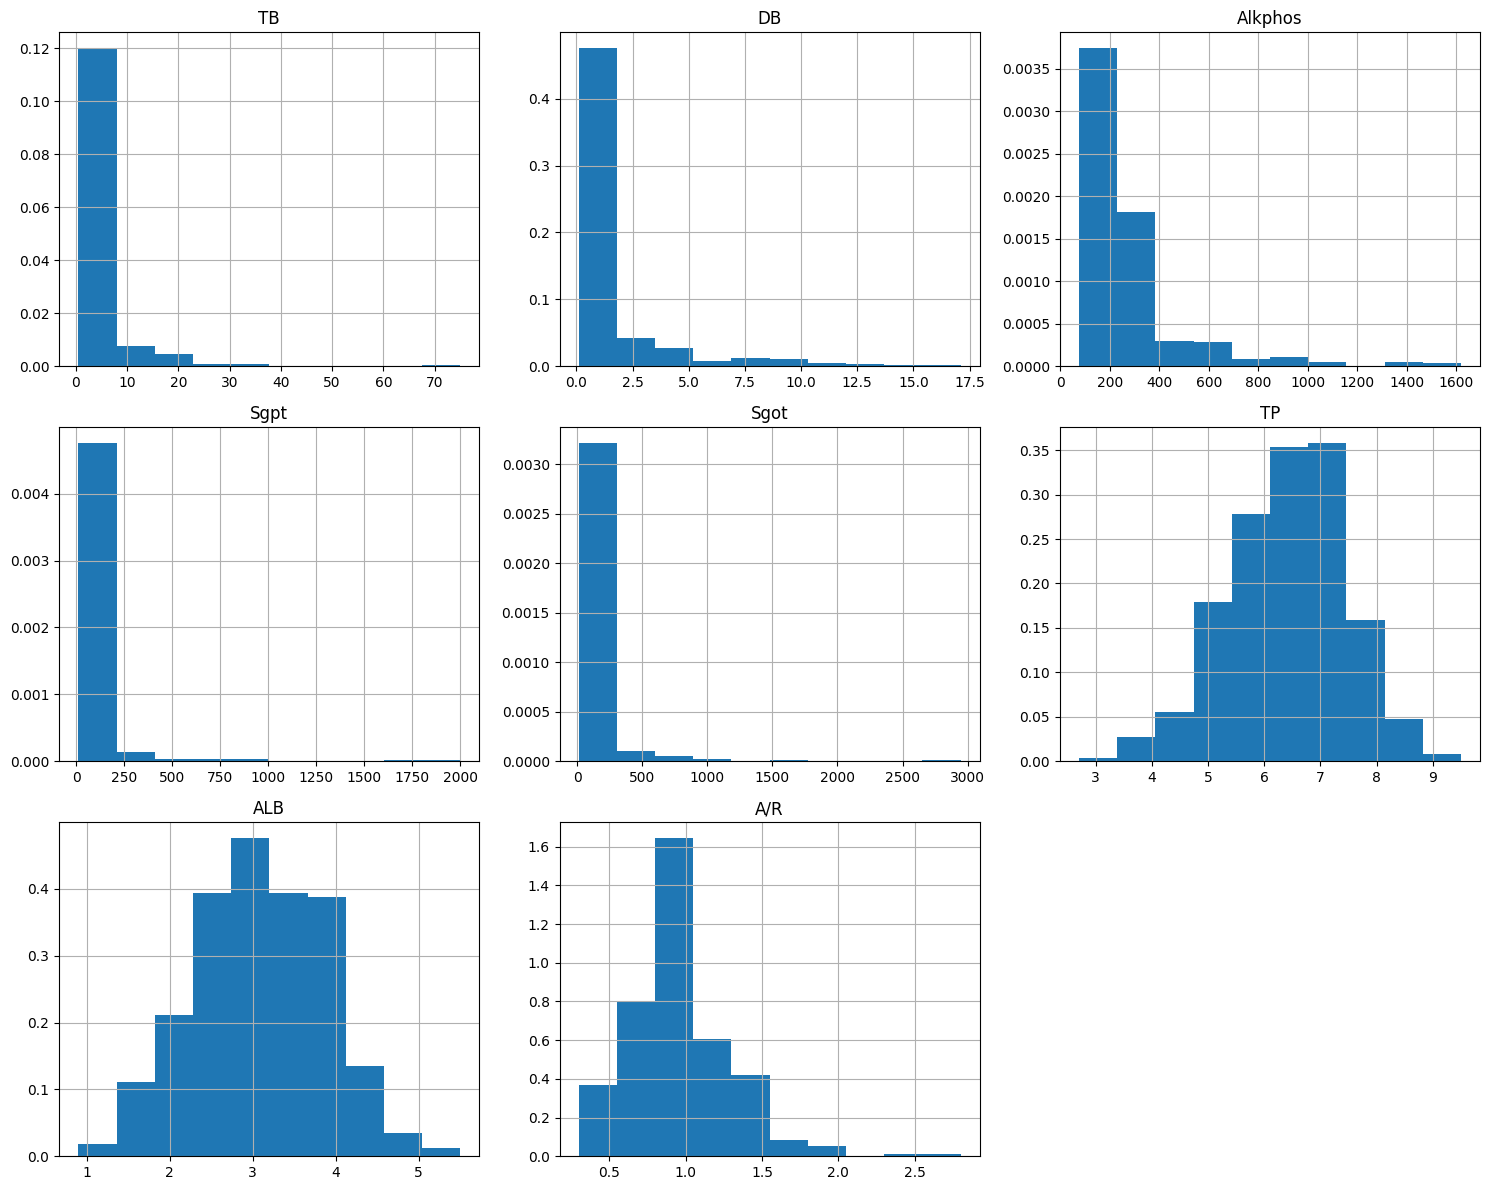

In [10]:
numeric_continuous_features = ["TB", "DB", "Alkphos", "Sgpt", "Sgot", "TP", "ALB", "A/R"]

num_numeric_continuous_features = len(numeric_continuous_features)
cols = 3
rows = ((num_numeric_continuous_features + cols - 1) // cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

for i, feature in enumerate(numeric_continuous_features):
    X_train[feature].hist(ax = axes[i], density=True)
    mu = X_train[feature].mean()
    sigma = X_train[feature].std()
    xmin, xmax = axes[i].get_xlim()
    x = np.linspace(xmin, xmax, 100)
    axes[i].set_title(feature)

# Amagar subgràfics sobrants si n'hi ha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Veiem que hi ha diverses variables que no segueixen res semblant a una gaussiana. Intentem millorar-ho.

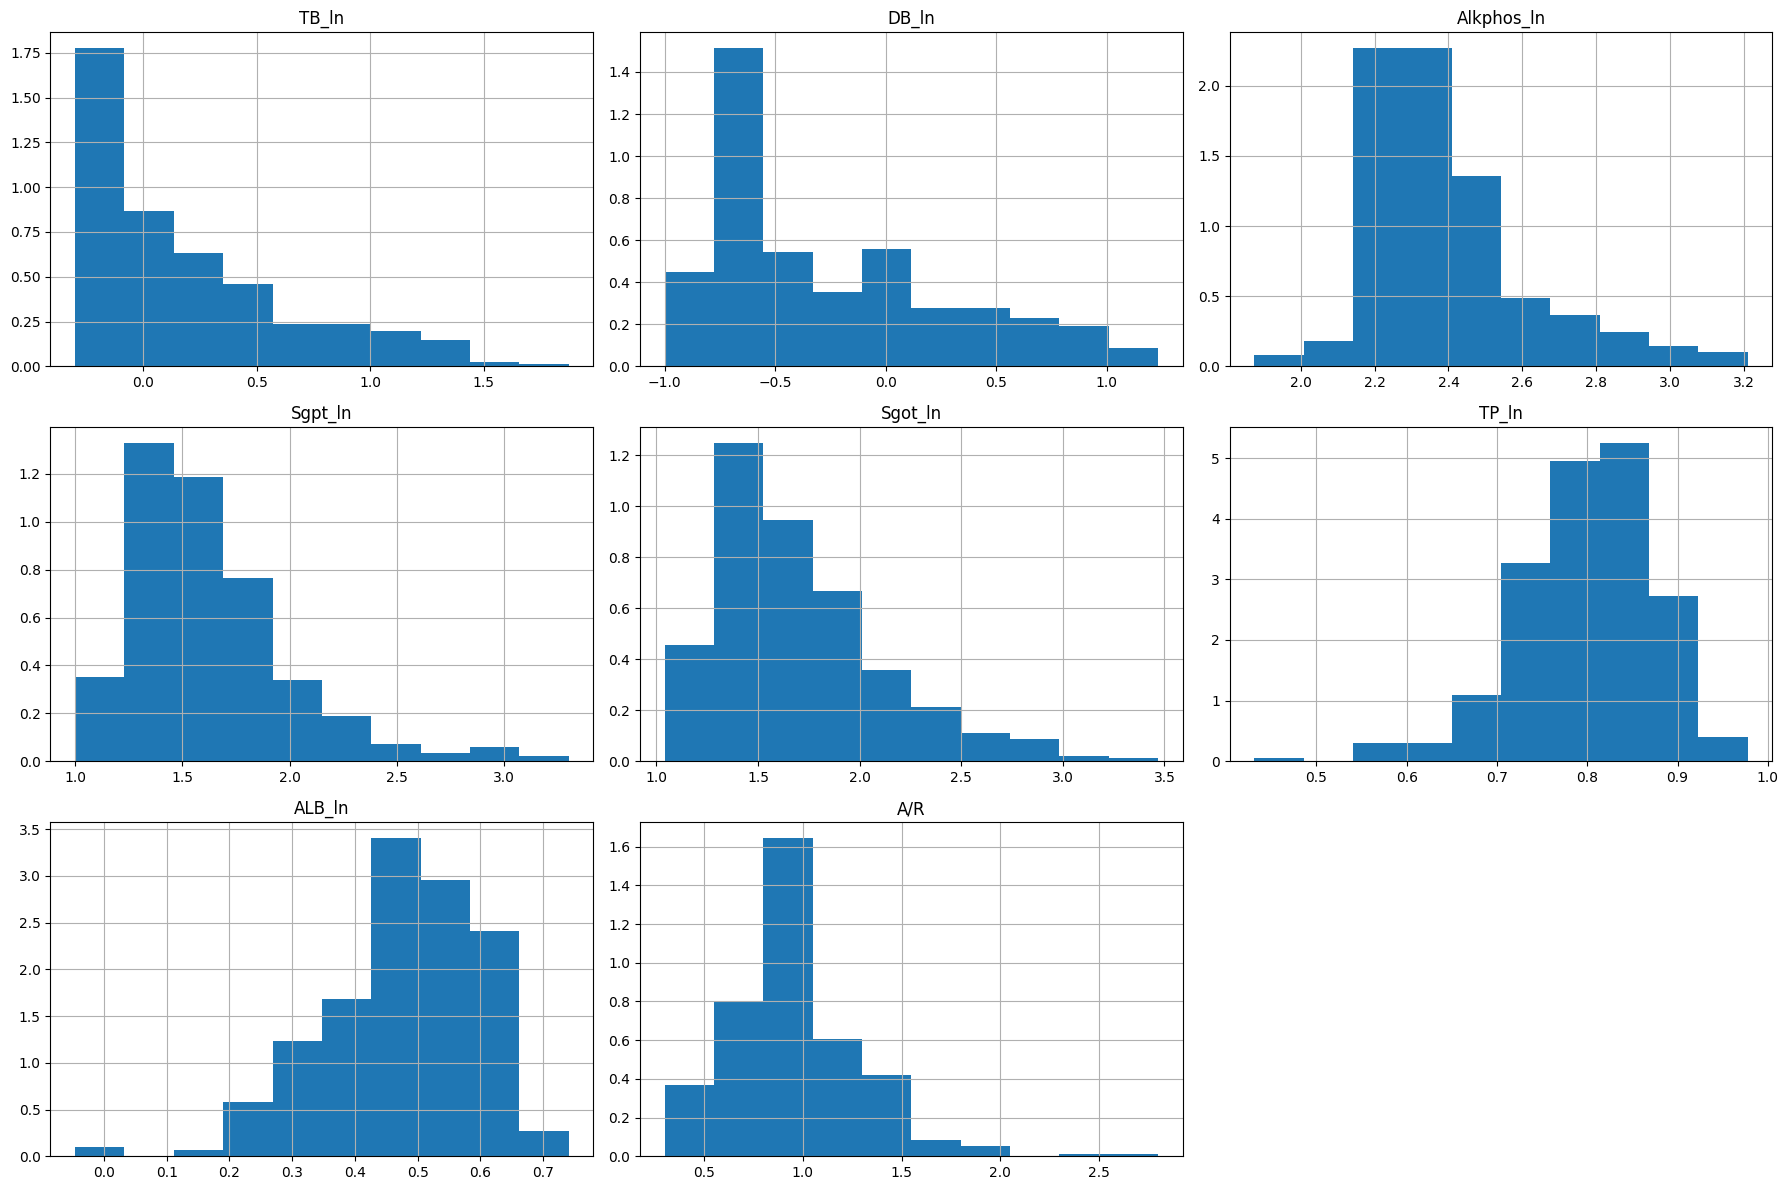

In [11]:
# Variables contínues a transformar
variables_asim = ["TB", "DB", "Alkphos", "Sgpt", "Sgot", "TP", "ALB"] # Per temes de simplicitat realitzarem ara el logaritme de TP i ALB, pero es justifica més endevant.

# Crear còpia de seguretat per visualitzar després de transformar
X_train_log10 = X_train.copy()

# Aplicar logaritme en base 10 a les variables asimètriques
for col in variables_asim:
    new_col_name = col + "_ln"
    X_train_log10[new_col_name] = np.log10(X_train_log10[col] + 1e-6)
    X_train_log10 = X_train_log10.drop(columns=[col])

numeric_continuous_features = ["TB_ln", "DB_ln", "Alkphos_ln", "Sgpt_ln", "Sgot_ln", "TP_ln", "ALB_ln", "A/R"]
features_to_plot = numeric_continuous_features
num_features_to_plot = len(features_to_plot)
cols = 3
rows = ((num_features_to_plot + cols - 1) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 4))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    if feature in X_train_log10.columns:
        X_train_log10[feature].hist(ax = axes[i], density=True)

        mu = X_train_log10[feature].mean()
        sigma = X_train_log10[feature].std()

        xmin, xmax = axes[i].get_xlim()
        x = np.linspace(xmin, xmax, 100)
        axes[i].set_title(feature)
    else:
        print(f"Warning: Feature '{feature}' not found in X_train_log10 after transformation.")
        fig.delaxes(axes[i]) 


# Amagar subgràfics sobrants si n'hi ha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

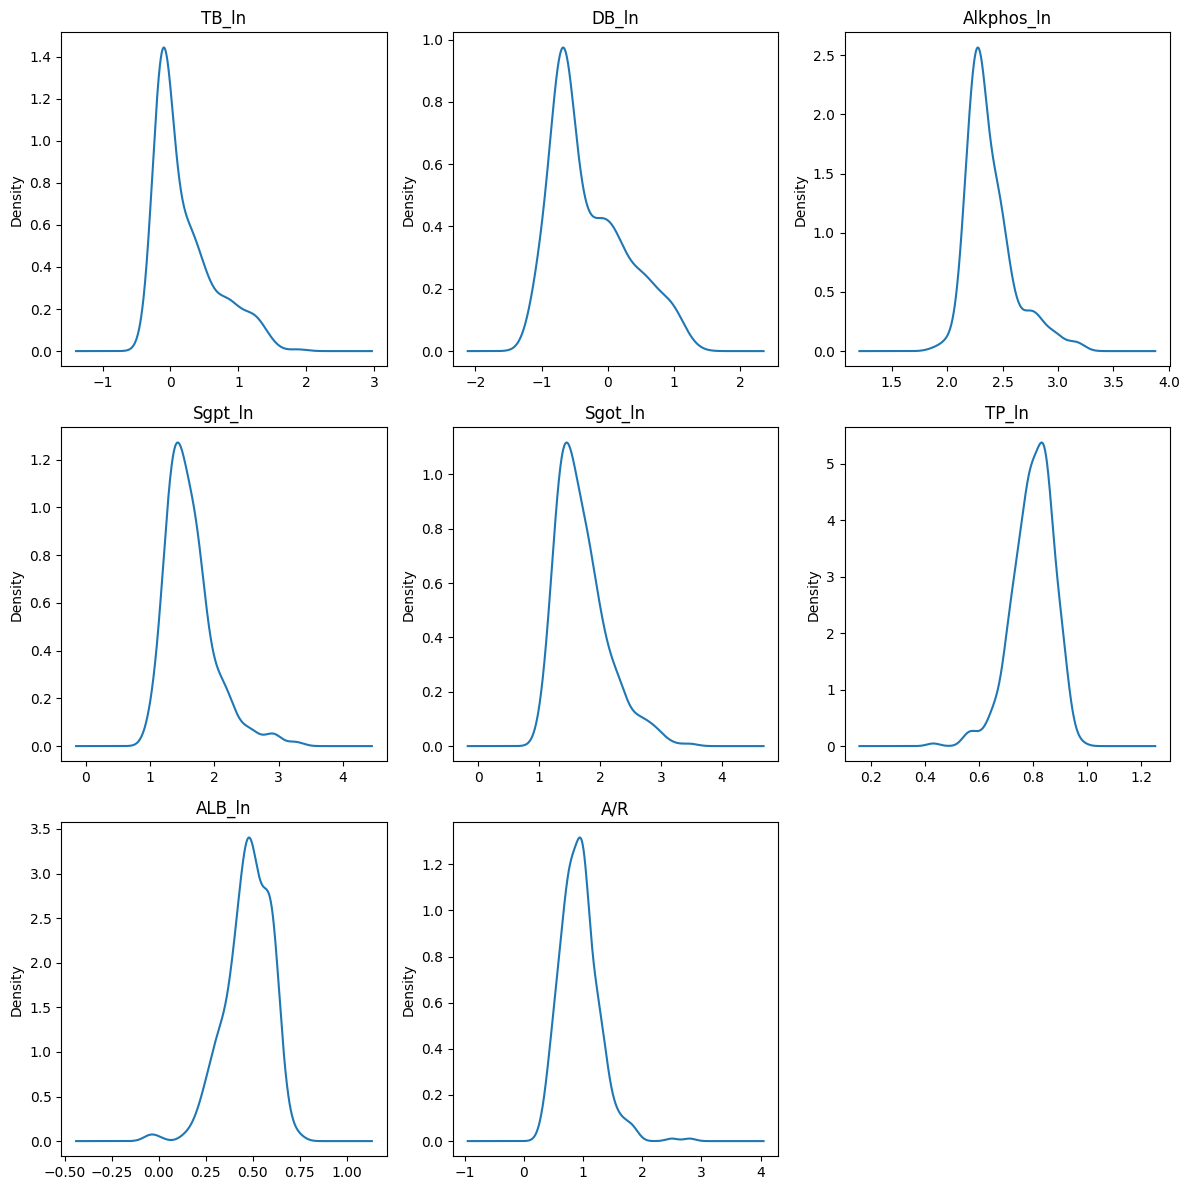

In [12]:
fig_kde = plt.figure(figsize=(12,12))
for i, feature in enumerate(numeric_continuous_features):
    ax_kde = fig_kde.add_subplot(3, 3, i+1)
    X_train_log10[feature].plot.kde(ax=ax_kde)
    ax_kde.set_title(feature)

fig_kde.tight_layout()
plt.show()

Tot i no seguir gaussianes perfectes, veiem com hem millorat.

### *Col·linealitat*

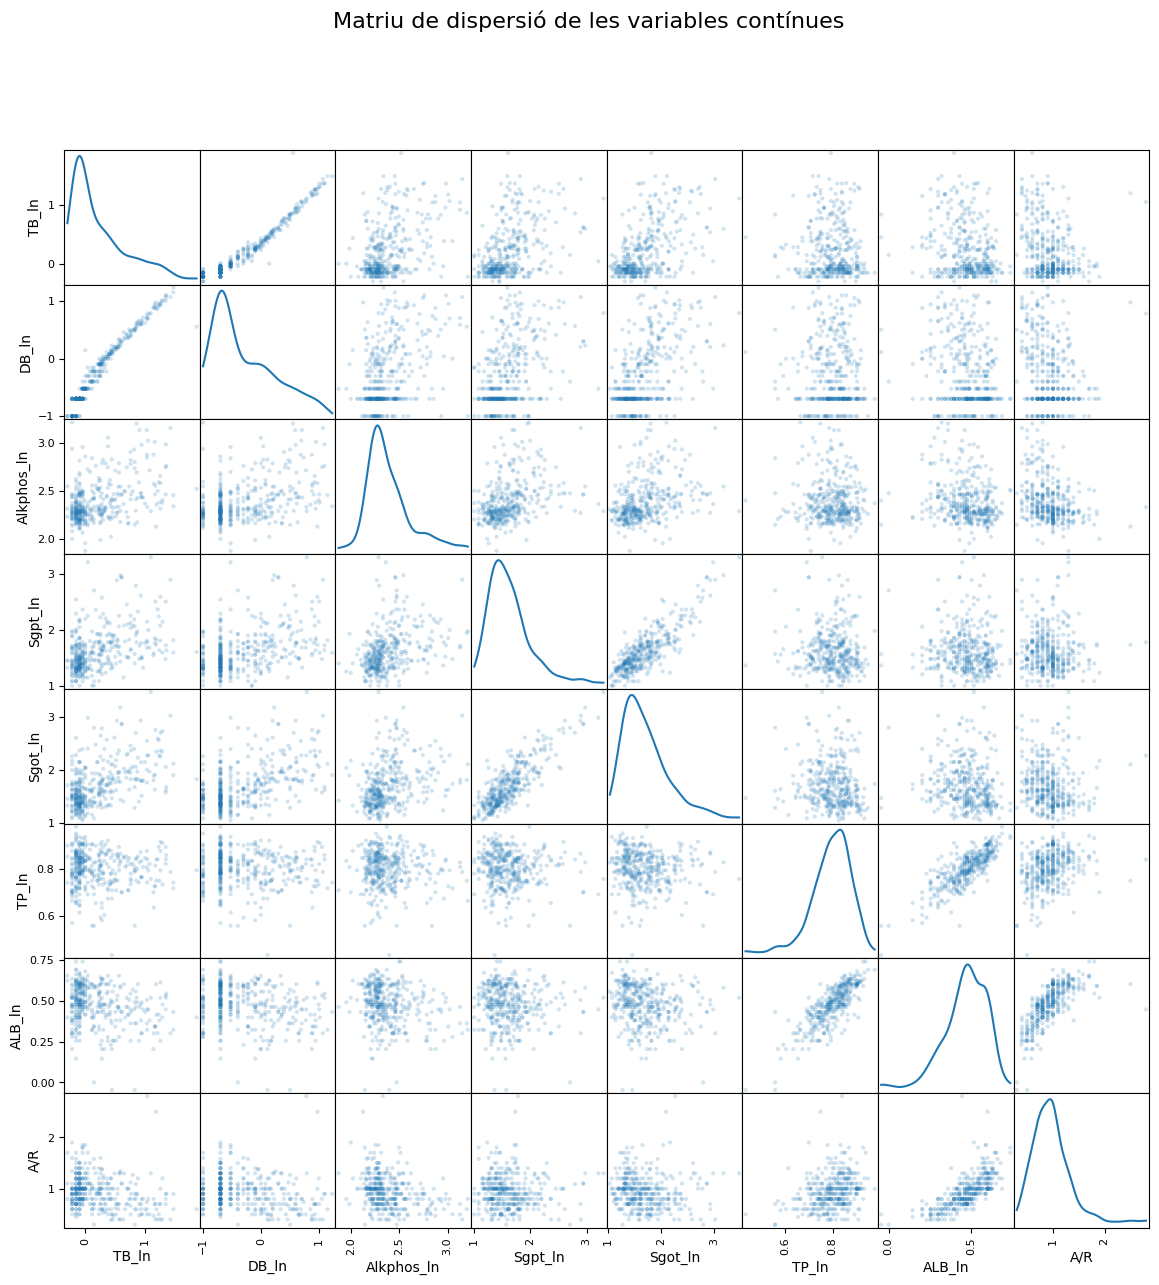

In [13]:
# Dades sense outliers i amb logaritmes aplicats (si ja ho tens fet)
X_train_log10_numeriques = X_train_log10[numeric_continuous_features]

# Matriu de dispersió
scatter_matrix(X_train_log10_numeriques,
               alpha=0.2,
               figsize=(14, 14),
               diagonal='kde',
               marker='.')

plt.suptitle("Matriu de dispersió de les variables contínues", fontsize=16)
plt.show()

Detectem una col·linealitat entre algunes variables. Això pot estar motivat pel rang de les variables, per tant, analitzem el rang.

In [14]:
X_train_log10_numeriques.describe()

,TB_ln,DB_ln,Alkphos_ln,Sgpt_ln,Sgot_ln,TP_ln,ALB_ln,A/R
count,3.700000e+02,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000
mean,2.087491e-01,-0.278992,2.385835,1.619722,1.700545,0.798799,0.474286,0.940676
std,4.402482e-01,0.566275,0.217984,0.380862,0.418215,0.076003,0.121060,0.324339
min,-3.010291e-01,-0.999996,1.875061,1.000000,1.041393,0.431364,-0.045757,0.300000
25%,-9.690947e-02,-0.698968,2.245513,1.361728,1.384643,0.755875,0.402199,0.700000
50%,4.342943e-07,-0.522877,2.321183,1.544068,1.612784,0.806180,0.477121,0.900000
75%,4.313639e-01,0.105253,2.472379,1.778151,1.921663,0.851258,0.568202,1.100000
max,1.875061e+00,1.232996,3.209515,3.301030,3.469233,0.977724,0.740363,2.800000


Ara veiem com totes les variables presenten rangs similars i podem procedir amb analitzar la col·linealitat.

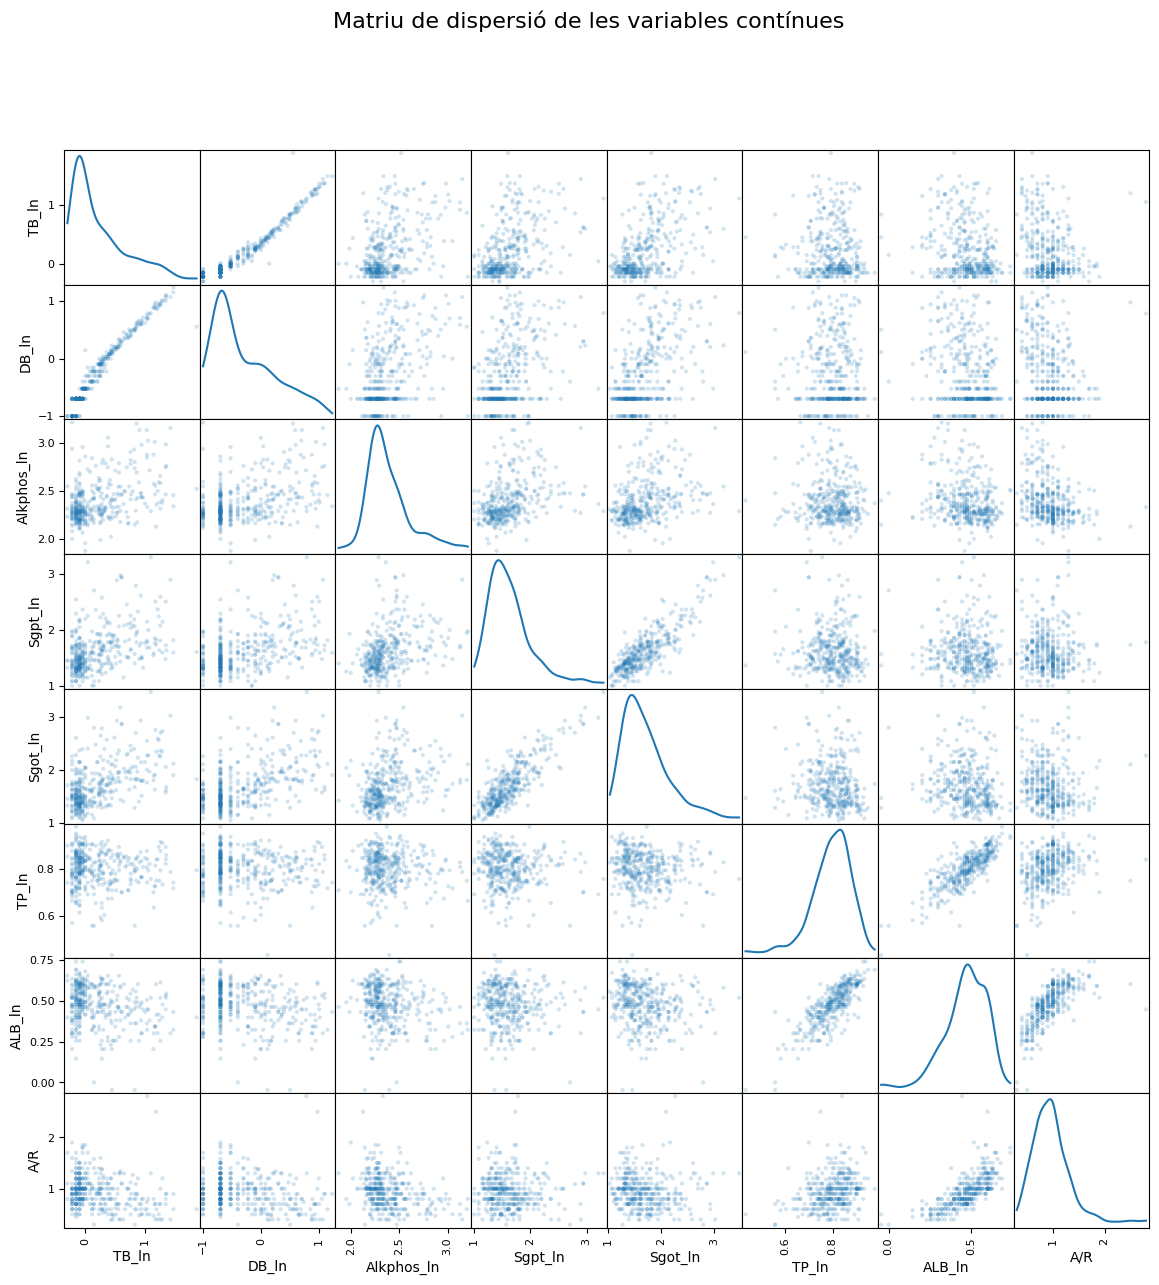

In [15]:
numeric_continuous_features=["A/R", "TB_ln", "DB_ln", "Alkphos_ln", "Sgpt_ln", "Sgot_ln", "TP_ln", "ALB_ln"]

# Matriu de dispersió
scatter_matrix(X_train_log10_numeriques,
               alpha=0.2,
               figsize=(14, 14),
               diagonal='kde',
               marker='.')

plt.suptitle("Matriu de dispersió de les variables contínues", fontsize=16)
plt.show()

Realitzem un HeatMap per tenir uns resultats més clarificadors.

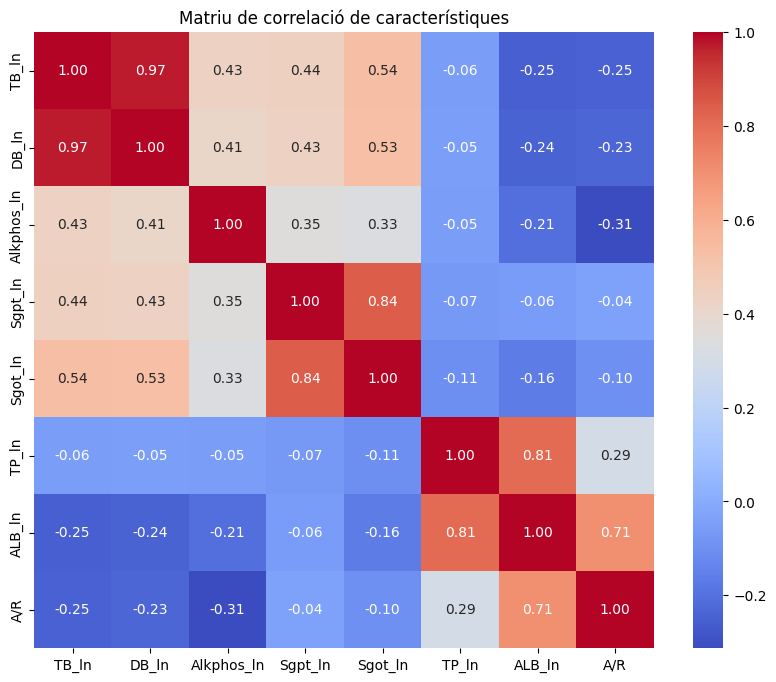

In [16]:
corr = X_train_log10_numeriques.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Matriu de correlació de característiques")
plt.show()

TB/DB presenten col·linealitat, podriem mirar de juntar-les o eliminar una. El que farem serà eliminar DB i quedar-nos amb TB. Això ja ho farem sobre el dataset de train.

In [17]:
X_train_log10.drop(columns=['DB_ln'], inplace=True)
X_train_preprocessed = X_train_log10.copy()
X_train_preprocessed.describe()

,Age,Female,A/R,TB_ln,Alkphos_ln,Sgpt_ln,Sgot_ln,TP_ln,ALB_ln
count,370.000000,370.000000,370.000000,3.700000e+02,370.000000,370.000000,370.000000,370.000000,370.000000
mean,44.710811,0.248649,0.940676,2.087491e-01,2.385835,1.619722,1.700545,0.798799,0.474286
std,16.002376,0.432815,0.324339,4.402482e-01,0.217984,0.380862,0.418215,0.076003,0.121060
min,4.000000,0.000000,0.300000,-3.010291e-01,1.875061,1.000000,1.041393,0.431364,-0.045757
25%,32.250000,0.000000,0.700000,-9.690947e-02,2.245513,1.361728,1.384643,0.755875,0.402199
50%,45.000000,0.000000,0.900000,4.342943e-07,2.321183,1.544068,1.612784,0.806180,0.477121
75%,57.000000,0.000000,1.100000,4.313639e-01,2.472379,1.778151,1.921663,0.851258,0.568202
max,78.000000,1.000000,2.800000,1.875061e+00,3.209515,3.301030,3.469233,0.977724,0.740363


Comprovem que totes les variables segueixen gaussianitat i no hi ha col·lineatitat

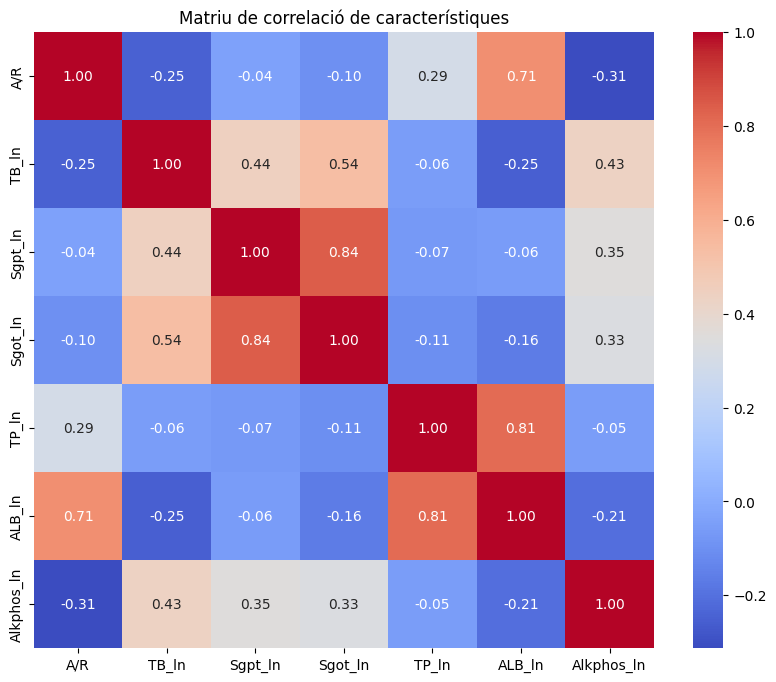

In [18]:
numeric_continuous_features=["A/R", "TB_ln", "Sgpt_ln", "Sgot_ln", "TP_ln", "ALB_ln", "Alkphos_ln"]
corr = X_train_preprocessed[numeric_continuous_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Matriu de correlació de característiques")
plt.show()

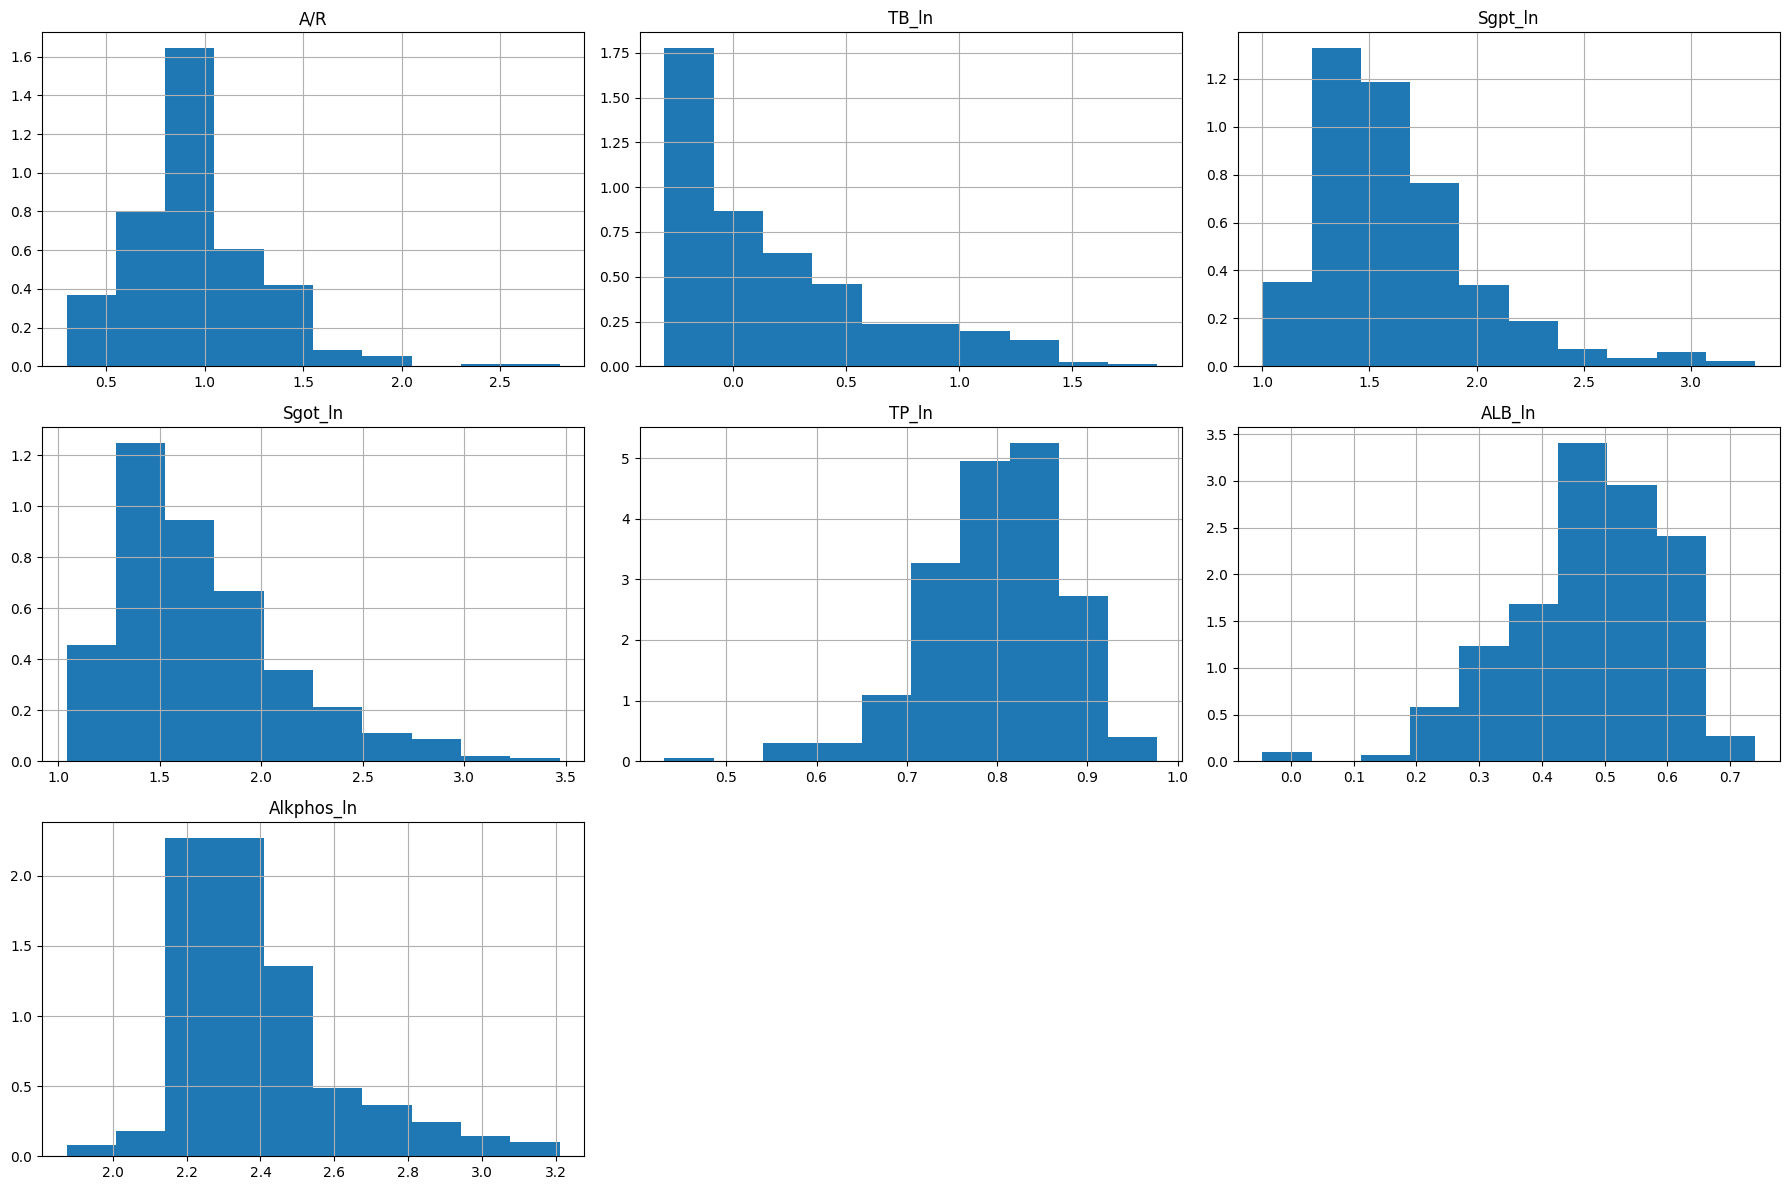

In [19]:
features_to_plot = numeric_continuous_features
num_features_to_plot = len(features_to_plot)
cols = 3
rows = ((num_features_to_plot + cols - 1) // cols)
fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 4))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    X_train_preprocessed[feature].hist(ax = axes[i], density=True)

    mu = X_train_preprocessed[feature].mean()
    sigma = X_train_preprocessed[feature].std()

    xmin, xmax = axes[i].get_xlim()
    x = np.linspace(xmin, xmax, 100)
    axes[i].set_title(feature)


# Amagar subgràfics sobrants si n'hi ha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Veiem com ara ja no tenim ni col·linealitat, ni NA's, les variables categòriques han estat tractades com a tal, totes s'aproximen una gaussiana, tenen un rang de valors semblant i hem derivat noves característiques reduïnt la col·linealitat i complexitat del nostre model

### *Pipeline que resumeix tot el preprocessat fet*

Per evitar qüestions de filtrat de dades, el que farem serà aplicar tot aquest preprocessat en un mateix pipeline

In [20]:
from sklearn.preprocessing import FunctionTransformer
import numpy as np
import pandas as pd

def preprocess_features(X):
    """
    Aplica la transformación log10, calcula el ratio Sgpt/Sgot y elimina variables originales.

    Args:
        X (pd.DataFrame): El DataFrame de entrada con características crudas.

    Returns:
        pd.DataFrame: El DataFrame con las características transformadas y escaladas (parcialmente).
    """
    X_transformed = X.copy()

    # Aplicar transformación log10 a variables asimétricas (excepto DB, Sgpt, Sgot)
    variables_asim_log10 = ["TB", "Alkphos", "ALB", "TP"]
    for col in variables_asim_log10:
        new_col_name = col + "_ln"
        # Añadir un pequeño valor para evitar logaritmo de cero o negativo
        X_transformed[new_col_name] = np.log10(X_transformed[col] + 1e-6)

    # Eliminar las columnas originales que ya no se usarán o han sido transformadas, incluyendo 'DB', 'Sgpt', 'Sgot'
    cols_to_drop = ["TB", "DB", "Alkphos", "TP", "ALB"]
    X_transformed = X_transformed.drop(columns=cols_to_drop, errors='ignore')

    # Definir el orden final de las columnas
    # Ahora incluimos 'TB_ln' y 'Sgpt/Sgot_ratio'
    final_cols_order = ['Age', 'Female', 'TP_ln', 'ALB_ln', 'A/R', 'Alkphos_ln', 'TB_ln', 'Sgpt', "Sgot"]

    # Seleccionar y reordenar las columnas que están presentes en X_transformed
    present_final_cols = [col for col in final_cols_order if col in X_transformed.columns]
    X_transformed = X_transformed[present_final_cols]

    return X_transformed

## **MODELLING**

### *Definim el dataframe i el pipeline que farem servir per entrenar els nostres models*

MODEL A CARREGAR SI ELIMINES OUTLIERS

In [21]:
def build_model_pipeline(model):
    """
    ImbPipeline:
      - preprocessing: FunctionTransformer con preprocess_features
      - scaler: passthrough o a elegir vía GridSearch
      - pca: passthrough o PCA a elegir
      - model: el clasificador
    """
    return ImbPipeline([
        ('preprocessing', FunctionTransformer(preprocess_features, validate=False)),
        ('scaler', 'passthrough'),
        ('pca', 'passthrough'),
        ('model', model)
    ])

### *Models i espais d'hiperparàmetres*

In [22]:
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    f1_score
)

scoring = {
    'accuracy': make_scorer(accuracy_score),
    'f1_1'   : make_scorer(f1_score, average='binary', pos_label=1),
    'f1_0'   : make_scorer(f1_score, average='binary', pos_label=0),
    'f1_macro': make_scorer(f1_score, average='macro')
}


In [23]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
balance = [None, 'balanced', 'balanced_subsample']
models_params = {
    'Logistic Regression': (
        build_model_pipeline(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
        [
            {
                'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
                'pca': [PCA(random_state=42)],
                'pca__n_components': [0.685, 0.69], #0.69
                'model__C': [0.18, 0.175], #0.175
                'model__solver': ['liblinear'],
                'model__class_weight': [None, 'balanced', 'balanced_subsample']

            },
        ]
    ),

    'Logistic Regression (L1)': (
        build_model_pipeline(LogisticRegression(class_weight='balanced', max_iter=2000, penalty='l1', solver='liblinear', random_state=42)),
        [
            {
                'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
                'pca': ['passthrough'],
                'model__C': [0.15, 0.2], #0.2
                'model__class_weight': [None, 'balanced', 'balanced_subsample']
            }
        ]
    ),

    'Random Forest': (
        build_model_pipeline(RandomForestClassifier(class_weight='balanced', random_state=42)),
        [
            {
                'scaler': ['passthrough'],
                'pca': ['passthrough'],
                'model__n_estimators': [193, 195, 196], #195
                'model__max_depth': [3, 100], #3
                'model__min_samples_split': [2], #2
                'model__min_samples_leaf': [10], #10
                'model__max_features': ['sqrt'],  # Nuevo parámetro
                'model__class_weight': [None, 'balanced', 'balanced_subsample']
            }
        ]
    ),

    'SVM (Linear)': (
    build_model_pipeline(SVC(class_weight='balanced', probability=True, random_state=42)),
    [
        {   # With PCA
            'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
            'pca': [PCA(random_state=42)],
            'pca__n_components': [0.685, 0.69], #0.69
            'model__kernel': ['linear'],
            'model__C': [1.45, 1.47], #1.45
            'model__class_weight': [None, 'balanced', 'balanced_subsample']
        },
    ]
),


    'SVM (RBF)': (
    build_model_pipeline(SVC(class_weight='balanced', probability=True, random_state=42)),
    [
        {  # With PCA
            'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
            'pca': [PCA(random_state=42)],
            'pca__n_components': [0.68, 0.69], #0.69
            'model__kernel': ['rbf'],
            'model__C': [78.2, 78.5, 79], #78.5
            'model__gamma': ['scale', 0.001], #0.001
            'model__class_weight': [None, 'balanced', 'balanced_subsample']
        },
    ]
),

    'KNN': (
    build_model_pipeline(KNeighborsClassifier()),
    [
        {  # With PCA
            'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
            'pca': [PCA(random_state=42)],
            'pca__n_components': [0.93, 0.935], #0.93
            'model__n_neighbors': [4, 5], #4
            'model__weights': ['distance'],
            'model__leaf_size': [1, 2], #1
            'model__metric': ['euclidean', 'manhattan'], #euclidian
        },
    ]
),

    'LDA': (
        build_model_pipeline(LinearDiscriminantAnalysis()),
        [
            {
                'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
                'pca': ['passthrough'],
                'model__solver': ['svd', 'lsqr', 'eigen'],
                'model__shrinkage': [None, 'auto'],
                'model__priors': [None],
                'model__n_components': [None, 550, 1],
                'model__store_covariance': [False],
                'model__tol': [1e-4, 0.1, 1e-3],
            }
        ]
    ),

    'QDA': (
        build_model_pipeline(QuadraticDiscriminantAnalysis()),
        [
            {
                'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
                'pca': ['passthrough'],
                'model__priors': [None],
                'model__reg_param': [1.1, 1.0, 1.2],
                'model__store_covariance': [True],
                'model__tol': [1e-4, 1e-3,0.001],
            }
        ]
    ),

    'Bagging + LR': (
    build_model_pipeline(BaggingClassifier(estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), random_state=42)),
    [
        {  # Without PCA
            'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
            'pca': [PCA(random_state=42)],
            'pca__n_components': [0.685, 0.69], #0.69
            'model__n_estimators': [35, 36], #36
            'model__max_samples': [0.73, 0.74], #0.74
            'model__max_features': [0.425, 0.43], #0.425
            'model__estimator__C': [1.45, 1.4], #1.45
            'model__estimator__solver': ['saga'],
            'model__estimator__penalty': ['l1'],
        }
    ]
),

    'Decision Tree': (
        build_model_pipeline(DecisionTreeClassifier(class_weight='balanced', random_state=42)),
        [
            {
                'scaler': ['passthrough'],
                'pca': ['passthrough'],
                'model__max_depth': [1,2], #2
                'model__min_samples_split': [1,2], #2
                'model__min_samples_leaf': [11, 12, 13], #11
                'model__class_weight': [None, 'balanced', 'balanced_subsample']
            }
        ]
    ),

    'Extra Trees': (
        build_model_pipeline(ExtraTreesClassifier(class_weight='balanced', random_state=42)),
        [
            {
                'scaler': ['passthrough'],
                'pca': ['passthrough'],
                'model__n_estimators': [310, 311, 312], #310
                'model__max_depth': [9, 10], #10
                'model__min_samples_split': [1, 2], #2
                'model__min_samples_leaf': [3, 4], #3
                'model__max_features': [0.44, 0.45, 0.46], # 0.45
                'model__class_weight': [None, 'balanced', 'balanced_subsample']
            }
        ]
    ),

    'Naive Bayes': (
        build_model_pipeline(GaussianNB()),
        [
            {
                'scaler': [StandardScaler(), RobustScaler(), MinMaxScaler()],
                'pca': ['passthrough'],
                'model__var_smoothing': [5e-10, 1e-9, 2e-9, 5e-9],
                'model__priors': [None],
            }
        ]
    )
}


Cerca del millor model

In [24]:
from sklearn.model_selection import GridSearchCV

best_score = 0
best_model = None
best_name = ''
best_params = None

all_model_results = {}

for name, (pipeline, params) in models_params.items():
    print(f"\nCercant hiperparámetres per: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring=scoring,       
        refit='f1_macro',
        cv=cv,
        n_jobs=-1, 
        verbose=1
    )

    search.fit(X_train, y_train_for_search)

    score = search.best_score_
    print(f"{name} -> F1 Score (CV): {score:.4f}")

    all_model_results[name] = {
        'best_score': score,
        'best_params': search.best_params_,
        'best_estimator': search.best_estimator_,
        'cv_results': search.cv_results_
    }

    if score > best_score:
        best_score   = score
        best_model   = search.best_estimator_
        best_name    = name
        best_params  = search.best_params_

print("\nMillor model rere GridSearchCV:")
print(f"Nom: {best_name}")
print(f"F1 Score (CV): {best_score:.4f}")
print(f"Hiperparámetres óptims: {best_params}")



Cercant hiperparámetres per: Logistic Regression
Fitting 50 folds for each of 36 candidates, totalling 1800 fits
Logistic Regression -> F1 Score (CV): 0.6419

Cercant hiperparámetres per: Logistic Regression (L1)
Fitting 50 folds for each of 18 candidates, totalling 900 fits
Logistic Regression (L1) -> F1 Score (CV): 0.6447

Cercant hiperparámetres per: Random Forest
Fitting 50 folds for each of 18 candidates, totalling 900 fits
Random Forest -> F1 Score (CV): 0.6468

Cercant hiperparámetres per: SVM (Linear)
Fitting 50 folds for each of 36 candidates, totalling 1800 fits
SVM (Linear) -> F1 Score (CV): 0.6092

Cercant hiperparámetres per: SVM (RBF)
Fitting 50 folds for each of 108 candidates, totalling 5400 fits
SVM (RBF) -> F1 Score (CV): 0.6274

Cercant hiperparámetres per: KNN
Fitting 50 folds for each of 48 candidates, totalling 2400 fits
KNN -> F1 Score (CV): 0.6216

Cercant hiperparámetres per: LDA
Fitting 50 folds for each of 162 candidates, totalling 8100 fits
LDA -> F1 Score 

In [25]:
df_results = pd.DataFrame.from_dict(all_model_results, orient='index')[['best_score', 'best_params']]

pd.set_option('display.max_colwidth', None)
pd.set_option('display.expand_frame_repr', False)

df_results = df_results.sort_values(by='best_score', ascending=False)

df_results


,best_score,best_params
Extra Trees,0.682452,"{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__max_features': 0.45, 'model__min_samples_leaf': 3, 'model__min_samples_split': 2, 'model__n_estimators': 310, 'pca': 'passthrough', 'scaler': 'passthrough'}"
Random Forest,0.646842,"{'model__class_weight': 'balanced_subsample', 'model__max_depth': 3, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'model__n_estimators': 196, 'pca': 'passthrough', 'scaler': 'passthrough'}"
Logistic Regression (L1),0.644680,"{'model__C': 0.15, 'model__class_weight': 'balanced', 'pca': 'passthrough', 'scaler': RobustScaler()}"
Logistic Regression,0.641877,"{'model__C': 0.18, 'model__class_weight': 'balanced', 'model__solver': 'liblinear', 'pca': PCA(random_state=42), 'pca__n_components': 0.685, 'scaler': StandardScaler()}"
Bagging + LR,0.638766,"{'model__estimator__C': 1.45, 'model__estimator__penalty': 'l1', 'model__estimator__solver': 'saga', 'model__max_features': 0.425, 'model__max_samples': 0.73, 'model__n_estimators': 36, 'pca': PCA(random_state=42), 'pca__n_components': 0.685, 'scaler': StandardScaler()}"
Decision Tree,0.634084,"{'model__class_weight': 'balanced', 'model__max_depth': 2, 'model__min_samples_leaf': 13, 'model__min_samples_split': 2, 'pca': 'passthrough', 'scaler': 'passthrough'}"
SVM (RBF),0.627358,"{'model__C': 79, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'rbf', 'pca': PCA(random_state=42), 'pca__n_components': 0.69, 'scaler': MinMaxScaler()}"
KNN,0.621576,"{'model__leaf_size': 1, 'model__metric': 'euclidean', 'model__n_neighbors': 5, 'model__weights': 'distance', 'pca': PCA(random_state=42), 'pca__n_components': 0.935, 'scaler': StandardScaler()}"
SVM (Linear),0.609250,"{'model__C': 1.45, 'model__class_weight': 'balanced', 'model__kernel': 'linear', 'pca': PCA(random_state=42), 'pca__n_components': 0.685, 'scaler': StandardScaler()}"
QDA,0.601672,"{'model__priors': None, 'model__reg_param': 1.0, 'model__store_covariance': True, 'model__tol': 0.0001, 'pca': 'passthrough', 'scaler': StandardScaler()}"


Executem ensemble methods. 

In [26]:
def prepare_base_models(all_model_results, top_n=5):
    """
    Prepara els millors models com a estimadors base per a un ensemble

    Paràmetres:
    -----------
    all_model_results : dict
        Diccionari amb resultats de GridSearchCV
    top_n : int
        Nombre de millors models a seleccionar

    Retorna:
    --------
    base_estimators : list
        Llista de tuplos (nom, estimador) per a l'ensemble
    """
    # Ordenar modelos por mejor score
    sorted_models = sorted(all_model_results.items(), 
                          key=lambda x: x[1]['best_score'], 
                          reverse=True)
    
    base_estimators = []
    print(f"📋 Seleccionant top {top_n} models per ensemble:")
    
    for i, (name, results) in enumerate(sorted_models[:top_n]):
        estimator = results['best_estimator']
        score = results['best_score']
        
        ensemble_name = f"{name.lower().replace(' ', '_')}"
        base_estimators.append((ensemble_name, estimator))
        
        print(f"  {i+1}. {name}: F1 = {score:.4f}")
    
    return base_estimators

Voting classifiers

In [27]:
def create_voting_classifiers(base_estimators, X_train, y_train, cv, scoring):
    """
    Crea i avalua VotingClassifiers (hard i soft voting)

    Paràmetres:
    -----------
    base_estimators : list
        Llista d'estimadors base
    X_train, y_train : array-like
        Dades d'entrenament
    cv : generador de validació creuada
        Generador de validació creuada
    scoring : dict
        Diccionari de mètriques d'avaluació

    Retorna:
    --------
    voting_results : dict
        Resultats dels voting classifiers
    """
    voting_results = {}
    
    print("\nVOTING CLASSIFIERS")
    print("=" * 50)
    
    # Hard Voting
    print("\nHard Voting Classifier")
    hard_voting = VotingClassifier(
        estimators=base_estimators,
        voting='hard'
    )
    
    # Evaluación con validación cruzada
    cv_scores = {}
    for metric_name, scorer in scoring.items():
        scores = cross_val_score(hard_voting, X_train, y_train, 
                               cv=cv, scoring=scorer, n_jobs=-1)
        cv_scores[metric_name] = {
            'mean': scores.mean(),
            'std': scores.std(),
            'scores': scores
        }
        print(f"  {metric_name}: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")
    
    voting_results['hard_voting'] = {
        'estimator': hard_voting,
        'cv_scores': cv_scores
    }
    
    # Soft Voting
    print("\n🔹 Soft Voting Classifier")
    try:
        soft_voting = VotingClassifier(
            estimators=base_estimators,
            voting='soft'
        )
        
        cv_scores = {}
        for metric_name, scorer in scoring.items():
            scores = cross_val_score(soft_voting, X_train, y_train, 
                                   cv=cv, scoring=scorer, n_jobs=-1)
            cv_scores[metric_name] = {
                'mean': scores.mean(),
                'std': scores.std(),
                'scores': scores
            }
            print(f"  {metric_name}: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")
        
        voting_results['soft_voting'] = {
            'estimator': soft_voting,
            'cv_scores': cv_scores
        }
        
    except Exception as e:
        print(f"  Soft voting no disponible: {str(e)}")
        print("  (Alguns models no soportan predict_proba)")
    
    return voting_results

Stacking classifier

In [28]:
def create_stacking_classifiers(base_estimators, X_train, y_train, cv, scoring):
    """
    Crea i avalua StackingClassifiers amb diferents meta-aprenents

    Paràmetres:
    -----------
    base_estimators : list
        Llista d'estimadors base
    X_train, y_train : array-like
        Dades d'entrenament
    cv : generador de validació creuada
        Generador de validació creuada
    scoring : dict
        Diccionari de mètriques d'avaluació

    Retorna:
    --------
    stacking_results : dict
        Resultats dels stacking classifiers
    """
    stacking_results = {}
    
    print("\nSTACKING CLASSIFIERS")
    print("=" * 50)
    
    meta_learners = {
        'logistic_regression': LogisticRegression(random_state=42, max_iter=1000),
        'random_forest': RandomForestClassifier(n_estimators=100, random_state=42)
    }
    
    for meta_name, meta_learner in meta_learners.items():
        print(f"\nStacking con {meta_name.replace('_', ' ').title()}")
        
        stacking_clf = StackingClassifier(
            estimators=base_estimators,
            final_estimator=meta_learner,
            cv=5,  
            stack_method='auto',
            n_jobs=-1
        )
        
        cv_scores = {}
        for metric_name, scorer in scoring.items():
            scores = cross_val_score(stacking_clf, X_train, y_train, 
                                   cv=cv, scoring=scorer, n_jobs=-1)
            cv_scores[metric_name] = {
                'mean': scores.mean(),
                'std': scores.std(),
                'scores': scores
            }
            print(f"  {metric_name}: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")
        
        stacking_results[f'stacking_{meta_name}'] = {
            'estimator': stacking_clf,
            'cv_scores': cv_scores,
            'meta_learner': meta_name
        }
    
    return stacking_results

In [29]:
def optimize_ensemble_hyperparameters(ensemble_estimator, param_grid, 
                                     X_train, y_train, cv, scoring):
    """
    Optimitza els hiperparàmetres d'un mètode ensemble

    Paràmetres:
    -----------
    ensemble_estimator : estimator
        Estimador ensemble a optimitzar
    param_grid : dict
        Reixeta (grid) d'hiperparàmetres
    X_train, y_train : array-like
        Dades d'entrenament
    cv : generador de validació creuada
        Generador de validació creuada
    scoring : dict
        Diccionari de mètriques d'avaluació

    Retorna:
    --------
    best_ensemble : estimator
        Millor estimador trobat
    """    
    grid_search = GridSearchCV(
        estimator=ensemble_estimator,
        param_grid=param_grid,
        scoring=scoring,
        refit='f1_macro',  
        cv=cv,
        n_jobs=-1,
        verbose=1
    )
    
    grid_search.fit(X_train, y_train)
    
    print(f"Millor score: {grid_search.best_score_:.4f}")
    print(f"Millors parámetres: {grid_search.best_params_}")
    
    return grid_search.best_estimator_, grid_search.best_params_

In [30]:
def compare_ensemble_results(voting_results, stacking_results, all_model_results):
    """
    Compara tots els resultats dels models ensemble amb els models individuals

    Paràmetres:
    -----------
    voting_results : dict
        Resultats dels classificadors per votació
    stacking_results : dict
        Resultats dels classificadors per stacking
    all_model_results : dict
        Resultats dels models individuals

    Retorna:
    --------
    comparison_df : DataFrame
        DataFrame amb la comparació de tots els models
    """
    print("\nCOMPARACIÓ DE RESULTATS")
    print("=" * 50)
    
    comparison_data = []
    
    # Afegir models individuals
    for name, results in all_model_results.items():
        comparison_data.append({
            'Model': name,
            'Type': 'Individual',
            'F1_Macro': results['best_score'],
            'Method': 'GridSearchCV'
        })
    
    # Afegir voting classifiers
    for name, results in voting_results.items():
        comparison_data.append({
            'Model': name.replace('_', ' ').title(),
            'Type': 'Ensemble (Voting)',
            'F1_Macro': results['cv_scores']['f1_macro']['mean'],
            'Method': 'Cross Validation'
        })
    
    # Afegir stacking classifiers
    for name, results in stacking_results.items():
        comparison_data.append({
            'Model': name.replace('_', ' ').title(),
            'Type': 'Ensemble (Stacking)',
            'F1_Macro': results['cv_scores']['f1_macro']['mean'],
            'Method': 'Cross Validation'
        })
    
    comparison_df = pd.DataFrame(comparison_data)
    comparison_df = comparison_df.sort_values('F1_Macro', ascending=False)
    
    return comparison_df

In [31]:
def plot_ensemble_comparison(comparison_df):
    """
    Visualitza la comparació de models
    """
    plt.figure(figsize=(12, 8))
    
    colors = {'Individual': 'skyblue', 
              'Ensemble (Voting)': 'lightcoral', 
              'Ensemble (Stacking)': 'lightgreen'}
    
    bars = plt.bar(range(len(comparison_df)), 
                   comparison_df['F1_Macro'],
                   color=[colors[t] for t in comparison_df['Type']])
    
    plt.xlabel('Modelos')
    plt.ylabel('F1 Macro Score')
    plt.title('Comparació: Models Individuals vs Ensemble Methods')
    plt.xticks(range(len(comparison_df)), 
               comparison_df['Model'], 
               rotation=45, ha='right')
    
    for i, bar in enumerate(bars):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.001,
                f'{height:.4f}', ha='center', va='bottom')
    
    legend_elements = [plt.Rectangle((0,0),1,1, color=color, label=label) 
                      for label, color in colors.items()]
    plt.legend(handles=legend_elements)
    
    plt.tight_layout()
    plt.show()

In [32]:
def evaluate_model_combinations(all_model_results, X_train, y_train, cv, scoring):
    """
    Evalúa diferents combinacions de models per trobar la millor
    """
    from itertools import combinations
    
    print("\nEVALUANT COMBINACIONS DE MODELS")
    print("=" * 50)
    
    sorted_models = sorted(all_model_results.items(), 
                          key=lambda x: x[1]['best_score'], 
                          reverse=True)
    
    top_models = dict(sorted_models[:6])  
    
    best_combination = None
    best_score = 0
    results = []
    
    for combo_size in [3, 4, 5]:
        print(f"\nProbant combinacions de {combo_size} models...")
        
        for combo in combinations(top_models.keys(), combo_size):
            estimators = [(name.lower().replace(' ', '_'), 
                          top_models[name]['best_estimator']) 
                         for name in combo]
            
            voting_clf = VotingClassifier(estimators=estimators, voting='soft')
            
            try:
                # Evaluar
                scores = cross_val_score(voting_clf, X_train, y_train, 
                                       cv=cv, scoring=scoring['f1_macro'], n_jobs=-1)
                mean_score = scores.mean()
                
                results.append({
                    'combination': combo,
                    'size': combo_size,
                    'f1_macro': mean_score,
                    'std': scores.std()
                })
                
                if mean_score > best_score:
                    best_score = mean_score
                    best_combination = (combo, estimators, mean_score)
                
                print(f"  {', '.join(combo[:2])}... -> F1: {mean_score:.4f}")
                
            except Exception as e:
                print(f"  Error con {combo}: {str(e)[:50]}...")
                continue
    
    if best_combination:
        print(f"\Millor combinació trobada:")
        print(f"  Models: {', '.join(best_combination[0])}")
        print(f"  F1 Score: {best_combination[2]:.4f}")
    
    return best_combination, results

In [33]:
import itertools
def optimize_voting_weights(base_estimators, X_train, y_train, cv, scoring):
    """
    Optimitza els pesos del VotingClassifier usant grid search
    """
    
    voting_clf = VotingClassifier(estimators=base_estimators, voting='soft')
    
    n_models = len(base_estimators)
    weight_options = [0.5, 1.0, 1.5, 2.0]
    
    weight_combinations = list(itertools.product(weight_options, repeat=min(n_models, 3)))
    
    if n_models > 3:
        extended_weights = []
        for base_weights in weight_combinations[:20]:  # Limitar a 20 combinacions
            full_weights = list(base_weights) + [1.0] * (n_models - len(base_weights))
            extended_weights.append(tuple(full_weights))
        weight_combinations = extended_weights
    
    param_grid = {'weights': weight_combinations}
    
    grid_search = GridSearchCV(
        estimator=voting_clf,
        param_grid=param_grid,
        scoring=scoring['f1_macro'],
        cv=cv,
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train, y_train)
    
    print(f"Millors pesos: {grid_search.best_params_['weights']}")
    print(f"Millor F1 Score: {grid_search.best_score_:.4f}")
    
    return grid_search.best_estimator_, grid_search.best_params_



EVALUANT COMBINACIONS DE MODELS

Probant combinacions de 3 models...
  Extra Trees, Random Forest... -> F1: 0.6623
  Extra Trees, Random Forest... -> F1: 0.6669
  Extra Trees, Random Forest... -> F1: 0.6686
  Extra Trees, Random Forest... -> F1: 0.6526
  Extra Trees, Logistic Regression (L1)... -> F1: 0.6662
  Extra Trees, Logistic Regression (L1)... -> F1: 0.6676
  Extra Trees, Logistic Regression (L1)... -> F1: 0.6500
  Extra Trees, Logistic Regression... -> F1: 0.6741
  Extra Trees, Logistic Regression... -> F1: 0.6502
  Extra Trees, Bagging + LR... -> F1: 0.6512
  Random Forest, Logistic Regression (L1)... -> F1: 0.6558
  Random Forest, Logistic Regression (L1)... -> F1: 0.6559
  Random Forest, Logistic Regression (L1)... -> F1: 0.6431
  Random Forest, Logistic Regression... -> F1: 0.6586
  Random Forest, Logistic Regression... -> F1: 0.6419
  Random Forest, Bagging + LR... -> F1: 0.6436
  Logistic Regression (L1), Logistic Regression... -> F1: 0.6442
  Logistic Regression (L1), L

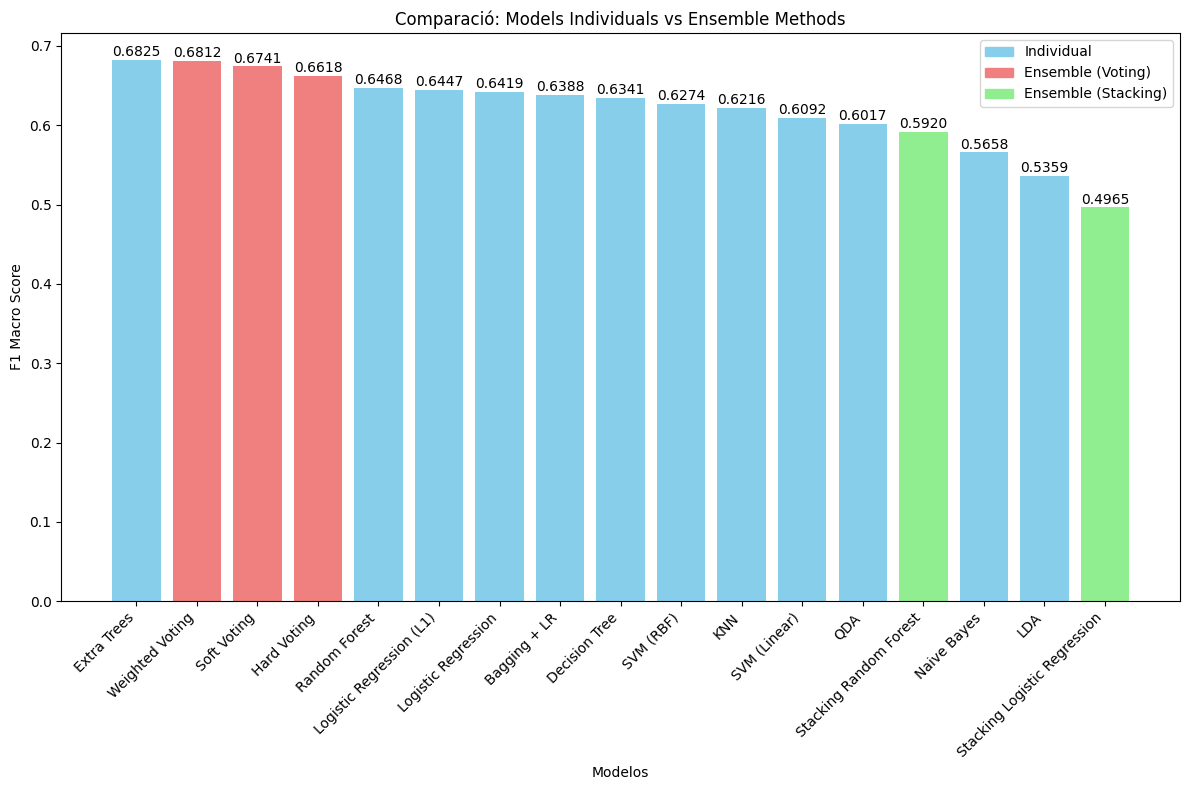

In [34]:
def run_ensemble_analysis(all_model_results, X_train, y_train, cv, scoring, top_n=5, 
                         use_advanced_selection=True, optimize_weights=True):
    """
    Executa l'anàlisi complet de mètodes ensemble (versió híbrida)

    Paràmetres:
    -----------
    all_model_results : dict
        Resultats de GridSearchCV dels models individuals
    X_train, y_train : array-like
        Dades d'entrenament
    cv : generador de validació creuada
        Generador de validació creuada
    scoring : dict
        Diccionari de mètriques d'avaluació
    top_n : int
        Nombre de millors models per a l'ensemble
    use_advanced_selection : bool
        Si s'utilitza selecció avançada de combinacions
    optimize_weights : bool
        Si s'optimitzen els pesos del classificador de votació

    Retorna:
    --------
    ensemble_results : dict
        Diccionari amb tots els resultats dels mètodes ensemble
    """    
    
    if use_advanced_selection:
        best_combination, combo_results = evaluate_model_combinations(
            all_model_results, X_train, y_train, cv, scoring)
        
        if best_combination:
            combo_models, base_estimators, combo_score = best_combination
            print(f"Millor combinació trobada: F1 = {combo_score:.4f}")
        else:
            print("Fallback a selecció tradicional")
            base_estimators = prepare_base_models(all_model_results, top_n)
    else:
        base_estimators = prepare_base_models(all_model_results, top_n)
    
    # 2. Crear Voting Classifiers 
    voting_results = create_voting_classifiers(base_estimators, X_train, y_train, cv, scoring)
    
    # 2b. Voting amb pesos optimitzats
    if optimize_weights:
        try:
            best_weighted_voting, best_weights = optimize_voting_weights(
                base_estimators, X_train, y_train, cv, scoring)
            
            cv_scores = {}
            for metric_name, scorer in scoring.items():
                scores = cross_val_score(best_weighted_voting, X_train, y_train, 
                                       cv=cv, scoring=scorer, n_jobs=-1)
                cv_scores[metric_name] = {
                    'mean': scores.mean(),
                    'std': scores.std(),
                    'scores': scores
                }
                print(f"  Weighted Voting {metric_name}: {scores.mean():.4f} (+/- {scores.std() * 2:.4f})")
            
            # Agregar a voting_results
            voting_results['weighted_voting'] = {
                'estimator': best_weighted_voting,
                'cv_scores': cv_scores,
                'weights': best_weights['weights']
            }
            
        except Exception as e:
            print(f"Error en optimització de pesos: {e}")
    
    # 3. Crear i evaluar Stacking Classifiers 
    stacking_results = create_stacking_classifiers(base_estimators, X_train, y_train, cv, scoring)
    
    # 4. Comparar resultats 
    comparison_df = compare_ensemble_results(voting_results, stacking_results, all_model_results)
    
    print("\nRANKING FINAL DE MODELS:")
    print(comparison_df.to_string(index=False))
    
    # 5. Análisis adicional 
    best_ensemble_score = comparison_df[comparison_df['Type'].str.contains('Ensemble')]['F1_Macro'].max()
    best_individual_score = comparison_df[comparison_df['Type'] == 'Individual']['F1_Macro'].max()
    
    print(f"\nANÁLISIS COMPARATIU:")
    print(f"   Millor model individual: {best_individual_score:.4f}")
    print(f"   Millor ensemble:         {best_ensemble_score:.4f}")
    
    if best_ensemble_score > best_individual_score:
        improvement = ((best_ensemble_score - best_individual_score) / best_individual_score) * 100
        print(f"   Millora del ensemble: +{improvement:.2f}%")
    else:
        decline = ((best_individual_score - best_ensemble_score) / best_individual_score) * 100
        print(f"   Ensemble pitjor que individual: -{decline:.2f}%")
    
    # 6. Visualització
    plot_ensemble_comparison(comparison_df)
    
    ensemble_results = {
        'base_estimators': base_estimators,
        'voting_results': voting_results,
        'stacking_results': stacking_results,
        'comparison_df': comparison_df,
        'diagnostics': {
            'best_individual_score': best_individual_score,
            'best_ensemble_score': best_ensemble_score
        }
    }
    
    if use_advanced_selection and 'best_combination' in locals():
        ensemble_results['advanced_selection'] = {
            'best_combination': best_combination,
            'combo_results': combo_results
        }
    
    return ensemble_results

ensemble_results = run_ensemble_analysis(
    all_model_results=all_model_results,
    X_train= X_train,
    y_train=y_train_for_search,
    cv=cv,
    scoring=scoring,
    top_n=3,                      
    use_advanced_selection=True,  
    optimize_weights=True         
)


## **Validació Externa y Visualizació del Error**

VALIDACIO EXTERNA DEL MILLOR MODEL

📈 RESULTATS DE VALIDACIÓ EXTERNA:
----------------------------------------
F1 Score (Macro): 0.6291
F1 Score (Weighted): 0.6709
Accuracy: 0.6559

🔍 COMPARACIÓ CV vs VALIDACIÓ EXTERNA:
---------------------------------------------
F1 Score (CV):        0.6825
F1 Score (External):  0.6291
Diferencia:           0.0533

REPORT DETALLAT DE CLASIFICACIÓ:
---------------------------------------------
              precision    recall  f1-score   support

           0       0.83      0.65      0.73        66
           1       0.44      0.67      0.53        27

    accuracy                           0.66        93
   macro avg       0.63      0.66      0.63        93
weighted avg       0.71      0.66      0.67        93


MATRIU DE CONFUSIÓ:
-------------------------
[[43 23]
 [ 9 18]]


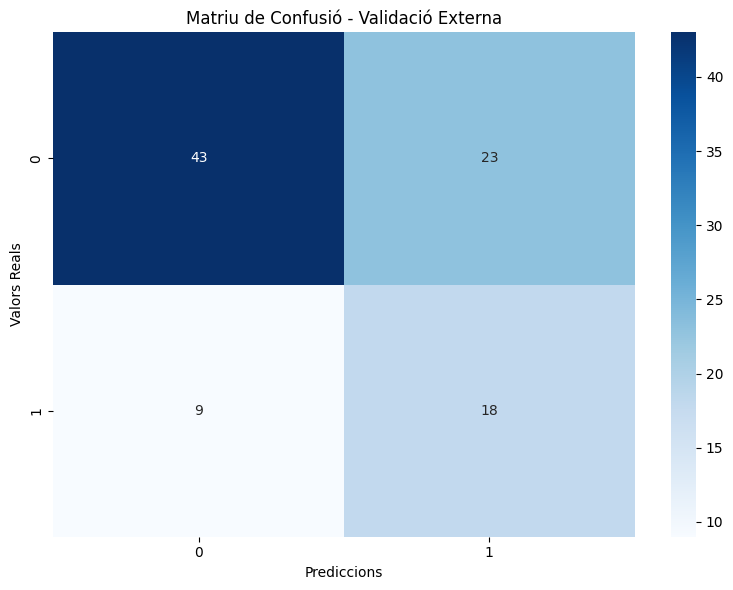


📊 ANÁLISIS PER CLASE:
-------------------------
Clase 0: Accuracy = 0.6515 (n=66)
Clase 1: Accuracy = 0.6667 (n=27)


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
print("="*60)
print("VALIDACIO EXTERNA DEL MILLOR MODEL")
print("="*60)


final_model = best_model
final_model.fit(X_train, y_train_for_search)

# 2. Realitzar prediccions en el conjunt de validació externa
y_pred_external = final_model.predict(X_validation_external_raw)

# 3. Calcular métriques de validació externa
print(f"\n📈 RESULTATS DE VALIDACIÓ EXTERNA:")
print("-" * 40)

# F1 Score macro
f1_external = f1_score(y_validation_external, y_pred_external, average='macro')
print(f"F1 Score (Macro): {f1_external:.4f}")

# F1 Score weighted
f1_weighted_external = f1_score(y_validation_external, y_pred_external, average='weighted')
print(f"F1 Score (Weighted): {f1_weighted_external:.4f}")

# Accuracy
accuracy_external = (y_validation_external == y_pred_external).mean()
print(f"Accuracy: {accuracy_external:.4f}")

print(f"\n🔍 COMPARACIÓ CV vs VALIDACIÓ EXTERNA:")
print("-" * 45)
print(f"F1 Score (CV):        {best_score:.4f}")
print(f"F1 Score (External):  {f1_external:.4f}")
print(f"Diferencia:           {abs(best_score - f1_external):.4f}")

print(f"\nREPORT DETALLAT DE CLASIFICACIÓ:")
print("-" * 45)
print(classification_report(y_validation_external, y_pred_external))

# 6. Matriz de confusión
print(f"\nMATRIU DE CONFUSIÓ:")
print("-" * 25)
cm = confusion_matrix(y_validation_external, y_pred_external)
print(cm)

# 7. Visualización de la matriz de confusión (opcional)
def plot_confusion_matrix(y_true, y_pred, title="Matriu de Confusió - Validació Externa"):
    """
    Funció per visualitzar la matriu de confusió
    """
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=np.unique(y_true), 
                yticklabels=np.unique(y_true))
    plt.title(title)
    plt.ylabel('Valors Reals')
    plt.xlabel('Prediccions')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(y_validation_external, y_pred_external)

print(f"\n📊 ANÁLISIS PER CLASE:")
print("-" * 25)
unique_classes = np.unique(y_validation_external)
for class_label in unique_classes:
    mask = y_validation_external == class_label
    class_accuracy = (y_validation_external[mask] == y_pred_external[mask]).mean()
    class_count = mask.sum()
    print(f"Clase {class_label}: Accuracy = {class_accuracy:.4f} (n={class_count})")


Afegir entrenament sobre tot el conjunt de dades de train + validation (X_train_raw).

In [36]:
best_model.fit(X_train_raw, y_train_raw)

Pipeline(steps=[('preprocessing',
                 FunctionTransformer(func=<function preprocess_features at 0x00000254132822A0>)),
                ('scaler', 'passthrough'), ('pca', 'passthrough'),
                ('model',
                 ExtraTreesClassifier(class_weight='balanced', max_depth=10,
                                      max_features=0.45, min_samples_leaf=3,
                                      n_estimators=310, random_state=42))])

## **Prediccions en el conjunt de test i generació submission.csv**

In [37]:
preds = best_model.predict(X_test_raw)

submission = pd.DataFrame({
    "ID": np.arange(1, len(preds) + 1),
    "Label": preds
})
submission.to_csv("submission.csv", index=False)
print("\n Submissió generada: 'submission.csv'")


 Submissió generada: 'submission.csv'
